# Stage 2: EDA of Kaggle tracking features

This notebook looks at the tracking context that only the Kaggle Shot Logs provide:
distance to the closest defender, shot clock, dribbles and touch time.

- **Data:** `data/processed/kaggle_features.parquet`, built by `scripts/02_features/05_build_kaggle_features.py`.
  These are Kaggle shots from the 2014-15 regular season (games up to 2015-03-04) matched one-to-one to
  nba_api shots, so location, shot value and the label (`SHOT_MADE_FLAG`) come from nba_api.
- Kaggle only covers 2014-15, so the hold-out season 2025-26 is not involved.
- Heaves (`is_heave == 1`) are removed in every figure: they are desperation shots and would distort FG%.
- **EDA informs feature design only.** No number computed here is fed into the model.

Every figure is saved as a PDF to `reports/figures/02_kaggle_<name>.pdf`.

## 0. Setup

Load the data, drop heaves and define the title text and the percent formatter used in every figure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RANGE = "NBA 2014-15 regular season, Kaggle Shot Logs (games to 2015-03-04)"
PCT = PercentFormatter(1.0, decimals=0)

df = pd.read_parquet("../data/processed/kaggle_features.parquet")
print(f"matched shots: {len(df):,}, heaves removed: {df['is_heave'].sum():,}")
df = df[df["is_heave"] == 0].reset_index(drop=True)
overall_fg = df["SHOT_MADE_FLAG"].mean()
print(f"shots used: {len(df):,}, overall FG%: {overall_fg:.3f}")

matched shots: 126,838, heaves removed: 476
shots used: 126,362, overall FG%: 0.454


## 1. Defender distance, controlled for shot distance

**What we check:** FG% as a function of the distance to the closest defender, separately for four groups of shots:
2s at the rim (0-4 ft), short 2s (4-14 ft), long 2s (14+ ft) and 3s.
**Why:** without this split the defender effect is hidden. Defenders are always close on shots at the rim
(which go in often) and far away on many 3s (which go in less often), so a single overall curve mixes
the effect of defence with the effect of distance (confounding). Looking within distance bands removes most of that.

median shot distance (ft) by defender bin, all shots:
def_bin
0-1      2.3
1-2      2.6
2-3      3.9
3-4     11.5
4-6     19.5
6-10    23.2
10+     23.7
                 n                                       fg                              
band    2PT 0-4 ft 2PT 14+ ft 2PT 4-14 ft    3PT 2PT 0-4 ft 2PT 14+ ft 2PT 4-14 ft    3PT
def_bin                                                                                  
0-1           4943        213        1876    122      0.504      0.300       0.358  0.205
1-2          10016        872        4695    442      0.523      0.329       0.349  0.240
2-3          12257       3005        7355   1643      0.576      0.352       0.387  0.285
3-4           6908       5444        5170   4154      0.680      0.374       0.408  0.322
4-6           4451      12248        4329  13764      0.762      0.407       0.445  0.348
6-10          1263       5920         791  10161      0.865      0.448       0.508  0.381
10+            465        886        

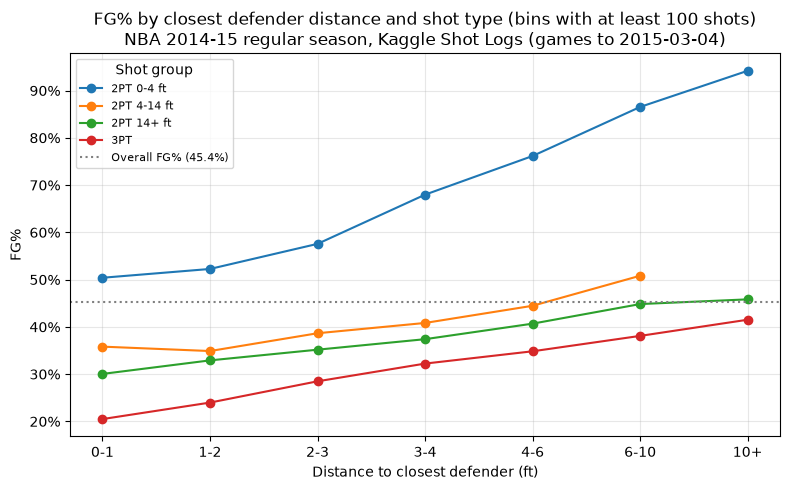

In [2]:
df["band"] = np.select(
    [df["is_three"] == 1, df["dist_ft"] < 4, df["dist_ft"] < 14],
    ["3PT", "2PT 0-4 ft", "2PT 4-14 ft"], default="2PT 14+ ft",
)
def_edges = [0, 1, 2, 3, 4, 6, 10, np.inf]
def_labels = ["0-1", "1-2", "2-3", "3-4", "4-6", "6-10", "10+"]
df["def_bin"] = pd.cut(df["close_def_dist"], def_edges, right=False, labels=def_labels)

print("median shot distance (ft) by defender bin, all shots:")
print(df.groupby("def_bin", observed=True)["dist_ft"].median().round(1).to_string())

by_def = df.groupby(["band", "def_bin"], observed=True)["SHOT_MADE_FLAG"].agg(n="size", fg="mean")
print(by_def.unstack(0).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
for band in ["2PT 0-4 ft", "2PT 4-14 ft", "2PT 14+ ft", "3PT"]:
    d = by_def.loc[band]
    d = d[d["n"] >= 100]  # hide unstable points
    ax.plot(d.index.astype(str), d["fg"], marker="o", label=band)
ax.axhline(overall_fg, color="grey", ls=":", label=f"Overall FG% ({overall_fg:.1%})")
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Distance to closest defender (ft)")
ax.set_ylabel("FG%")
ax.set_title(f"FG% by closest defender distance and shot type (bins with at least 100 shots)\n{RANGE}")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, title="Shot group")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_kaggle_defender_by_distance.pdf")
plt.show()

**Observations**

- Within every distance band FG% rises steadily as the defender gets further away:
  - at the rim (0-4 ft) from 50.4% (defender within 1 ft) to 86.5% (6-10 ft) and 94.2% (10+ ft),
  - short 2s (4-14 ft) from 35.8% to 50.8% (6-10 ft),
  - long 2s (14+ ft) from 30.0% to 45.8%,
  - 3s from 20.5% (within 1 ft, only 122 shots) to 38.1% (6-10 ft) and 41.5% (10+ ft).
- The overall curve hides this because of confounding: the median shot distance is 2.3 ft when the
  defender is within 1 ft and 23.2 ft when the defender is 6-10 ft away.
- Defender distance is therefore a strong feature, but only together with shot distance. A model without it
  (nba_api only) will treat a wide-open and a tightly contested shot from the same spot as equal.

## 2. Shot clock

**What we check:** FG% vs the time left on the shot clock (2-s bins), separately for 2s and 3s. Shots taken while
the shot clock was turned off (end of period) are excluded. Shots with exactly 24.0 s are shown as a separate point.
**Why:** late in the shot clock players are forced into hurried shots; very early shots are often fast breaks
or putbacks. The feature may add information that location does not have.

              n           fg       
is_three      0     1      0      1
sc_bin                             
[0, 2)     2068  1017  0.340  0.243
[2, 4)     4289  1773  0.404  0.321
[4, 6)     6229  2184  0.435  0.362
[6, 8)     8236  2849  0.456  0.353
[8, 10)   10347  3304  0.465  0.365
[10, 12)  11646  3770  0.474  0.371
[12, 14)  11440  3839  0.477  0.369
[14, 16)  10396  3664  0.477  0.370
[16, 18)   7548  3446  0.506  0.363
[18, 20)   6165  3387  0.557  0.381
[20, 22)   5188  1533  0.662  0.374
[22, 24)   2745   600  0.562  0.363

shot_clock == 24.0: 3,665 shots, median distance 1.2 ft
action_group
tip_putback    0.54
layup          0.21
dunk           0.16


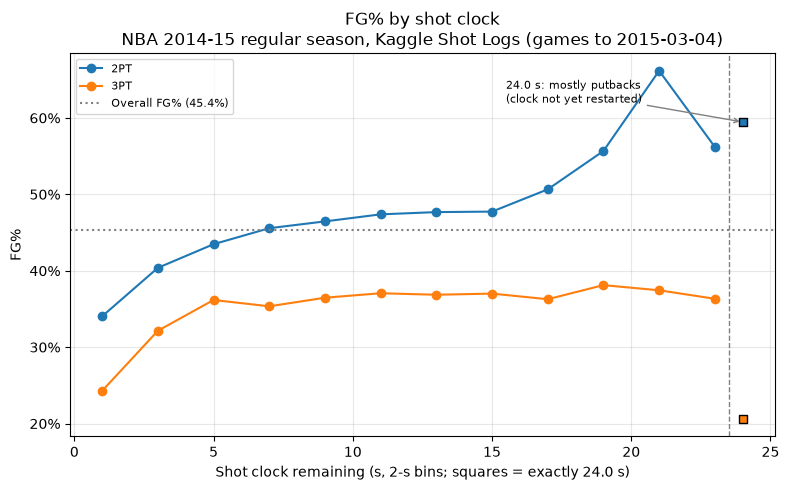

In [3]:
sc = df[df["shot_clock_off"] == 0].dropna(subset=["shot_clock"]).copy()
sc["sc_bin"] = pd.cut(sc["shot_clock"], np.arange(0, 26, 2), right=False)
by_sc = sc[sc["shot_clock"] < 24].groupby(["sc_bin", "is_three"], observed=True)["SHOT_MADE_FLAG"].agg(n="size", fg="mean").unstack()
print(by_sc.round(3).to_string())

full = sc[sc["shot_clock"] == 24]
print(f"\nshot_clock == 24.0: {len(full):,} shots, median distance {full['dist_ft'].median():.1f} ft")
print(full["action_group"].value_counts(normalize=True).head(3).round(2).to_string())
fg24 = full.groupby("is_three")["SHOT_MADE_FLAG"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
x = [iv.left + 1 for iv in by_sc.index]
for v, label, color in [(0, "2PT", "tab:blue"), (1, "3PT", "tab:orange")]:
    ax.plot(x, by_sc[("fg", v)], marker="o", color=color, label=label)
    ax.scatter([24], [fg24[v]], marker="s", color=color, edgecolor="black", zorder=3)
ax.axvline(23.5, color="grey", ls="--", lw=1)
ax.annotate("24.0 s: mostly putbacks\n(clock not yet restarted)", (24, fg24[0]), xytext=(15.5, 0.62),
            fontsize=8, arrowprops=dict(arrowstyle="->", color="grey"))
ax.axhline(overall_fg, color="grey", ls=":", label=f"Overall FG% ({overall_fg:.1%})")
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Shot clock remaining (s, 2-s bins; squares = exactly 24.0 s)")
ax.set_ylabel("FG%")
ax.set_title(f"FG% by shot clock\n{RANGE}")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_kaggle_shot_clock.pdf")
plt.show()

**Observations**

- Late in the shot clock both 2s and 3s get worse: with 0-2 s left 2PT FG% is 34.0% and 3PT FG% 24.3%,
  compared with about 47% and 37% in the middle of the clock (10-16 s).
- 2PT FG% rises sharply early in the clock (55.7% at 18-20 s, 66.2% at 20-22 s): these are fast breaks and
  putbacks, i.e. easy shots close to the rim. 3PT FG% stays flat at 36-38% from 6 s upwards.
- Shots at exactly 24.0 s (3,665 shots, median distance 1.2 ft) are 54% tip/putbacks, 21% layups and 16% dunks.
  This confirms they are putbacks after an offensive rebound where the clock had not restarted, not a data error.
  The 3PT square is based on only 68 shots (20.6%), most likely clock recording errors, and should not be read as a trend.
- Useful features: the shot clock itself and possibly a "late clock" indicator (under about 4 s).

## 3. Dribbles before the shot

**What we check:** FG% by the number of dribbles before the shot (0, 1, 2, 3-5, 6-10, 11+), separately for 2s and 3s.
**Why:** shots without dribbles are usually catch-and-shoot or close finishes after a pass; many dribbles usually mean
a self-created shot against a set defence.

              n            fg       
is_three      0      1      0      1
dr_bin                              
0         36862  25368  0.545  0.366
1         16563   2564  0.476  0.340
2         12580   1113  0.441  0.280
3-5       14513   1959  0.448  0.309
6-10       8336   1443  0.440  0.328
11+        4322    739  0.425  0.344


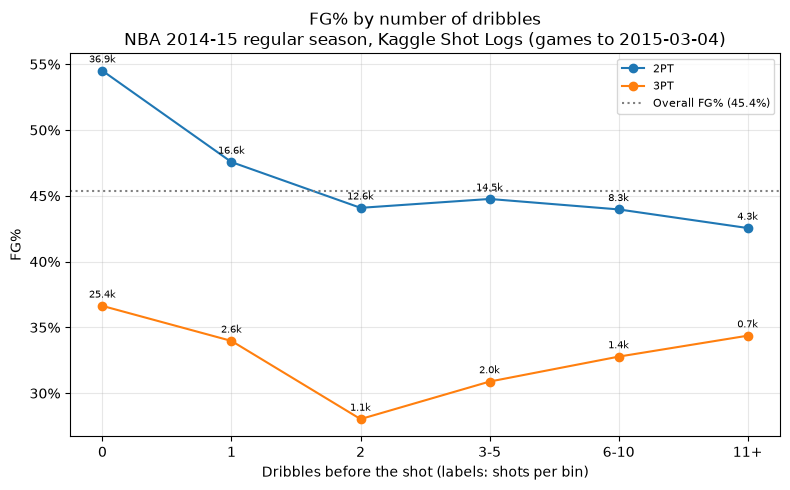

In [4]:
dr_labels = ["0", "1", "2", "3-5", "6-10", "11+"]
df["dr_bin"] = pd.cut(df["dribbles"], [0, 1, 2, 3, 6, 11, np.inf], right=False, labels=dr_labels)
by_dr = df.groupby(["dr_bin", "is_three"], observed=True)["SHOT_MADE_FLAG"].agg(n="size", fg="mean").unstack()
print(by_dr.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
for v, label in [(0, "2PT"), (1, "3PT")]:
    ax.plot(dr_labels, by_dr[("fg", v)], marker="o", label=label)
    for xi, (fg, n) in enumerate(zip(by_dr[("fg", v)], by_dr[("n", v)])):
        ax.annotate(f"{n / 1000:.1f}k", (xi, fg), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7)
ax.axhline(overall_fg, color="grey", ls=":", label=f"Overall FG% ({overall_fg:.1%})")
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Dribbles before the shot (labels: shots per bin)")
ax.set_ylabel("FG%")
ax.set_title(f"FG% by number of dribbles\n{RANGE}")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_kaggle_dribbles.pdf")
plt.show()

**Observations**

- 2s without a dribble are the best (54.5%); with 1 dribble 47.6%, and from 2 dribbles on FG% is flat at about 43-45%.
- 3s without a dribble go in at 36.6%, with 2 dribbles only 28.0%. With more dribbles 3PT FG% recovers a bit
  (31-34%), but these groups are small (under 2,000 shots each).
- Most of the difference is between 0 and 1+ dribbles, so a simple "no dribble" flag (or the catch-and-shoot flag
  in figure 4) captures most of the signal. Part of the 2PT effect is again distance: shots without a dribble
  include putbacks and cuts at the rim.

## 4. Catch-and-shoot

**What we check:** FG% for catch-and-shoot shots (`is_catch_shoot`: no dribble and the ball held at most 2 s)
against all other shots, for 3s and for 2PT jump shots from 10 ft or more (action groups jumper, pull-up,
step-back and fadeaway).
**Why:** comparing only jump shots from a similar range keeps the comparison fair; shots at the rim are left out.

               group            type     n    fg
                 3PT Catch-and-shoot 24724 0.368
                 3PT           Other  8462 0.319
2PT jumpers (10+ ft) Catch-and-shoot 12496 0.423
2PT jumpers (10+ ft)           Other 22815 0.385


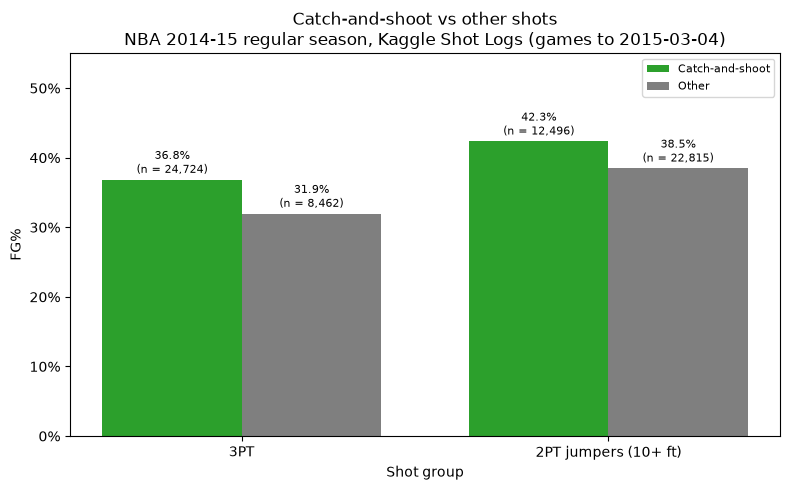

In [5]:
jumper_groups = ["jumper", "pullup_jumper", "stepback_jumper", "fadeaway_jumper"]
groups = {
    "3PT": df[df["is_three"] == 1],
    "2PT jumpers (10+ ft)": df[(df["is_three"] == 0) & (df["dist_ft"] >= 10) & df["action_group"].isin(jumper_groups)],
}
rows = []
for name, d in groups.items():
    for cs, label in [(1, "Catch-and-shoot"), (0, "Other")]:
        s = d.loc[d["is_catch_shoot"] == cs, "SHOT_MADE_FLAG"]
        rows.append({"group": name, "type": label, "n": len(s), "fg": s.mean()})
cs_table = pd.DataFrame(rows)
print(cs_table.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
width = 0.38
x = np.arange(len(groups))
for i, (label, color) in enumerate([("Catch-and-shoot", "tab:green"), ("Other", "tab:grey")]):
    d = cs_table[cs_table["type"] == label]
    bars = ax.bar(x + (i - 0.5) * width, d["fg"], width, color=color, label=label)
    for b, fg, n in zip(bars, d["fg"], d["n"]):
        ax.text(b.get_x() + b.get_width() / 2, fg + 0.01, f"{fg:.1%}\n(n = {n:,})", ha="center", fontsize=8)
ax.set_xticks(x, list(groups))
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, 0.55)
ax.set_xlabel("Shot group")
ax.set_ylabel("FG%")
ax.set_title(f"Catch-and-shoot vs other shots\n{RANGE}")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_kaggle_catch_and_shoot.pdf")
plt.show()

**Observations**

- Catch-and-shoot 3s go in at 36.8% vs 31.9% for other 3s (about +5 percentage points); they are also the
  large majority of 3s (24,724 vs 8,462).
- For 2PT jump shots from 10 ft or more the gap is similar: 42.3% vs 38.5% (about +4 points).
- Shooting off the catch is easier than creating a shot off the dribble, and the effect holds within comparable
  shot types, so `is_catch_shoot` is worth testing as a feature in the Kaggle model.

## Summary for feature design

- `close_def_dist` is the strongest new feature, but its effect only shows when shot distance is controlled for
  (confounding). The model must include both.
- `shot_clock`: hurried shots late in the clock are worse; early-clock 2s are easy putbacks and fast breaks.
  Values of exactly 24.0 s are real putbacks, not errors.
- `dribbles` / `is_catch_shoot`: the main difference is between no dribble and some dribbles; catch-and-shoot
  jump shots are about 4-5 percentage points better.
- These features exist only for about 127k shots of 2014-15, so they are used in a separate comparison model
  (nba_api features vs nba_api + Kaggle features on the same shots), not in the main xPTS model.